In [1]:
# Verify exported water-quality files
from pathlib import Path
import pandas as pd

output_folder = Path("final_datasets")

files_to_check = [
    "berlin_water_quality_2022_2026.csv",
    "berlin_water_temperature_monthly_2022_2024.csv",
    "berlin_bacteria_metadata.csv"
]

for filename in files_to_check:
    file_path = output_folder / filename

    if file_path.exists():
        check_df = pd.read_csv(file_path)
        print(f"\n{filename}")
        print("Shape:", check_df.shape)
        print("File size:", round(file_path.stat().st_size / 1024, 2), "KB")
    else:
        print(f"\nMISSING: {filename}")


berlin_water_quality_2022_2026.csv
Shape: (298, 28)
File size: 40.2 KB

berlin_water_temperature_monthly_2022_2024.csv
Shape: (176, 8)
File size: 12.94 KB

berlin_bacteria_metadata.csv
Shape: (2, 3)
File size: 0.1 KB


In [ ]:

#IMPORT LIBRARIES


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# DISPLAY SETTINGS


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:

#LOAD EXPORTED DATASETS


from pathlib import Path

# Define the folder containing the exported files
data_folder = Path("final_datasets")

# Load the combined bathing water-quality dataset
water_quality = pd.read_csv(
    data_folder / "berlin_water_quality_2022_2026.csv",
    parse_dates=["date"]
)

# Load historical monthly water temperatures (2022–2024)
monthly_water_temperature = pd.read_csv(
    data_folder / "berlin_water_temperature_monthly_2022_2024.csv"
)

# Load bacterial measurement metadata
bacteria_metadata = pd.read_csv(
    data_folder / "berlin_bacteria_metadata.csv"
)

# Display dataset dimensions
print("Water quality:", water_quality.shape)
print("Historical monthly temperature:", monthly_water_temperature.shape)
print("Bacteria metadata:", bacteria_metadata.shape)

Water quality: (298, 28)
Historical monthly temperature: (176, 8)
Bacteria metadata: (2, 3)


In [ ]:
#INSPECT THE WATER-QUALITY DATASET


# Display column names and data types
print("COLUMNS AND DATA TYPES")
display(water_quality.dtypes.to_frame(name="data_type"))

# Display the first five records
print("\nFIRST FIVE RECORDS")
display(water_quality.head())

# Display the historical temperature dataset
print("\nHISTORICAL TEMPERATURE DATA")
display(monthly_water_temperature.head())

# Display bacterial metadata
print("\nBACTERIAL METADATA")
display(bacteria_metadata)

COLUMNS AND DATA TYPES


,data_type
date,datetime64[us]
bathing_water_quality,str
coliform_bacteria,str
cyanobacteria_chl_a,str
e_coli,str
intestinal_enterococci,str
water_visibility_depth,str
water_temperature,str
lake,str
water_temperature_raw,str



FIRST FIVE RECORDS


,date,bathing_water_quality,coliform_bacteria,cyanobacteria_chl_a,e_coli,intestinal_enterococci,water_visibility_depth,water_temperature,lake,water_temperature_raw,water_temperature_qualifier,water_temperature_numeric,temperature_zero_flag,coliform_bacteria_raw,coliform_bacteria_qualifier,coliform_bacteria_numeric,e_coli_raw,e_coli_qualifier,e_coli_numeric,intestinal_enterococci_raw,intestinal_enterococci_qualifier,intestinal_enterococci_numeric,cyanobacteria_chl_a_raw,cyanobacteria_chl_a_qualifier,cyanobacteria_chl_a_numeric,water_visibility_depth_raw,water_visibility_depth_qualifier,water_visibility_depth_numeric
0,2022-04-20,NaN,NaN,NaN,"< 15,00","< 15,00","0,00",NaN,Flughafensee,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"< 15,00",<,15.00,"< 15,00",<,15.00,NaN,NaN,NaN,"0,00",NaN,0.00
1,2022-05-17,NaN,NaN,NaN,"< 15,00","< 15,00","0,00",NaN,Flughafensee,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"< 15,00",<,15.00,"< 15,00",<,15.00,NaN,NaN,NaN,"0,00",NaN,0.00
2,2022-05-31,NaN,NaN,NaN,"< 15,00","15,00","> 1,00",NaN,Flughafensee,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"< 15,00",<,15.00,"15,00",NaN,15.00,NaN,NaN,NaN,"> 1,00",>,1.00
3,2022-06-13,NaN,NaN,NaN,"< 15,00","< 15,00","> 1,00",NaN,Flughafensee,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"< 15,00",<,15.00,"< 15,00",<,15.00,NaN,NaN,NaN,"> 1,00",>,1.00
4,2022-06-27,NaN,NaN,NaN,"15,00","15,00","> 1,00",NaN,Flughafensee,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"15,00",NaN,15.00,"15,00",NaN,15.00,NaN,NaN,NaN,"> 1,00",>,1.00



HISTORICAL TEMPERATURE DATA


,Monat,monthly_mean_temp,monthly_min_temp,monthly_max_temp,n_obs,lake,measurement_method,year
0,2022-01,4.40,4.24,4.55,31,Flughafensee,Continuous monitoring,2022
1,2022-02,4.56,4.38,4.83,28,Flughafensee,Continuous monitoring,2022
2,2022-03,6.09,5.69,6.61,31,Flughafensee,Continuous monitoring,2022
3,2022-04,9.50,9.03,10.00,30,Flughafensee,Continuous monitoring,2022
4,2022-05,18.20,17.51,18.93,31,Flughafensee,Continuous monitoring,2022



BACTERIAL METADATA


,parameter,unit,lower_quantification_limit
0,e_coli,KBE/100 ml,15
1,intestinal_enterococci,KBE/100 ml,15


In [ ]:
#CLASSIFY BACTERIAL RESULTS

def classify_bacterial_results(df, parameter):
    qualifier_col = f"{parameter}_qualifier"
    raw_col = f"{parameter}_raw"
    result_col = f"{parameter}_result_type"

    # Identify results reported below the quantification limit
    below_limit = df[qualifier_col].eq("<")

    # Identify raw values starting with the text "null"
    null_prefix = (
        df[raw_col]
        .str.strip()
        .str.lower()
        .str.startswith("null", na=False)
    )

    # Identify records without a qualifier
    no_qualifier = df[qualifier_col].isna()

    # Assign result categories
    conditions = [
        below_limit,
        no_qualifier & null_prefix,
        no_qualifier & ~null_prefix
    ]

    categories = [
        "below quantification limit",
        "unqualified — null prefix",
        "unqualified — no null prefix"
    ]

    df[result_col] = np.select(
        conditions,
        categories,
        default="other qualifier"
    )

    return df


# Apply classification to both bacterial parameters
water_quality = classify_bacterial_results(water_quality, "e_coli")

water_quality = classify_bacterial_results(
    water_quality,
    "intestinal_enterococci"
)

# Display classification counts
for parameter in ["e_coli", "intestinal_enterococci"]:
    result_col = f"{parameter}_result_type"

    print(f"\n{parameter.upper()}")
    display(
        water_quality[result_col]
        .value_counts(dropna=False)
        .to_frame(name="records")
    )


E_COLI


,records
e_coli_result_type,
below quantification limit,189
unqualified — no null prefix,91
unqualified — null prefix,18



INTESTINAL_ENTEROCOCCI


,records
intestinal_enterococci_result_type,
below quantification limit,240
unqualified — no null prefix,53
unqualified — null prefix,5


In [ ]:
#DATASET OVERVIEW

# Overall dataset dimensions and coverage
print("DATASET OVERVIEW")
print("Records:", len(water_quality))
print("Lakes:", water_quality["lake"].nunique())
print("First sampling date:", water_quality["date"].min())
print("Last sampling date:", water_quality["date"].max())

# Records per lake
print("\nRECORDS PER LAKE")
display(
    water_quality["lake"]
    .value_counts()
    .sort_index()
    .to_frame(name="records")
)

# Records per year
print("\nRECORDS PER YEAR")
display(
    water_quality["date"]
    .dt.year
    .value_counts()
    .sort_index()
    .to_frame(name="records")
)

# Records per lake and year
print("\nRECORDS PER LAKE AND YEAR")
display(
    pd.crosstab(
        water_quality["lake"],
        water_quality["date"].dt.year
    )
)

# Missing values in each column
print("\nMISSING VALUES")
missing_summary = pd.DataFrame({
    "missing_records": water_quality.isna().sum(),
    "missing_percent": water_quality.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

display(missing_summary.round(2))

DATASET OVERVIEW
Records: 298
Lakes: 6
First sampling date: 2022-04-20 00:00:00
Last sampling date: 2026-09-15 00:00:00

RECORDS PER LAKE


,records
lake,
Flughafensee,49
Müggelsee,51
Orankesee,49
Tegeler See,50
Wannsee,49
Weißensee,50



RECORDS PER YEAR


,records
date,
2022,56
2023,61
2024,63
2025,58
2026,60



RECORDS PER LAKE AND YEAR


date,2022,2023,2024,2025,2026
lake,,,,,
Flughafensee,9,11,10,9,10
Müggelsee,10,10,11,10,10
Orankesee,9,10,10,10,10
Tegeler See,10,10,10,10,10
Wannsee,9,10,11,9,10
Weißensee,9,10,11,10,10



MISSING VALUES


,missing_records,missing_percent
water_temperature_qualifier,298,100.00
cyanobacteria_chl_a_qualifier,298,100.00
cyanobacteria_chl_a_raw,244,81.88
cyanobacteria_chl_a_numeric,244,81.88
cyanobacteria_chl_a,244,81.88
bathing_water_quality,216,72.48
coliform_bacteria_qualifier,194,65.10
water_temperature_numeric,183,61.41
water_temperature_raw,182,61.07
water_temperature,182,61.07


In [ ]:
#MEASUREMENT AVAILABILITY

# Numeric measurement columns
measurement_columns = {
    "Water temperature": "water_temperature_numeric",
    "Coliform bacteria": "coliform_bacteria_numeric",
    "E. coli": "e_coli_numeric",
    "Intestinal enterococci": "intestinal_enterococci_numeric",
    "Cyanobacteria": "cyanobacteria_chl_a_numeric",
    "Water visibility depth": "water_visibility_depth_numeric"
}

# Overall measurement availability
availability = pd.DataFrame({
    "parameter": measurement_columns.keys(),
    "available_records": [
        water_quality[col].notna().sum()
        for col in measurement_columns.values()
    ]
})

availability["missing_records"] = (
    len(water_quality) - availability["available_records"]
)

availability["available_percent"] = (
    availability["available_records"] / len(water_quality) * 100
)

print("OVERALL MEASUREMENT AVAILABILITY")
display(availability.round(2))

# Measurement availability by lake
lake_availability = pd.DataFrame(index=sorted(water_quality["lake"].unique()))

for parameter, column in measurement_columns.items():
    lake_availability[parameter] = (
        water_quality.groupby("lake")[column]
        .apply(lambda x: x.notna().sum())
    )

print("\nAVAILABLE MEASUREMENTS BY LAKE")
display(lake_availability)

# Water temperature availability by lake and year
water_quality["year"] = water_quality["date"].dt.year

temperature_coverage = (
    water_quality
    .groupby(["lake", "year"])["water_temperature_numeric"]
    .agg(
        available="count",
        total="size"
    )
)

temperature_coverage["available_percent"] = (
    temperature_coverage["available"] /
    temperature_coverage["total"] * 100
)

print("\nWATER TEMPERATURE AVAILABILITY BY LAKE AND YEAR")
display(temperature_coverage.round(1))

OVERALL MEASUREMENT AVAILABILITY


,parameter,available_records,missing_records,available_percent
0,Water temperature,115,183,38.59
1,Coliform bacteria,117,181,39.26
2,E. coli,298,0,100.00
3,Intestinal enterococci,298,0,100.00
4,Cyanobacteria,54,244,18.12
5,Water visibility depth,279,19,93.62



AVAILABLE MEASUREMENTS BY LAKE


,Water temperature,Coliform bacteria,E. coli,Intestinal enterococci,Cyanobacteria,Water visibility depth
Flughafensee,19,19,49,49,8,47
Müggelsee,20,20,51,51,10,51
Orankesee,19,20,49,49,9,37
Tegeler See,19,19,50,50,10,47
Wannsee,18,19,49,49,9,49
Weißensee,20,20,50,50,8,48



WATER TEMPERATURE AVAILABILITY BY LAKE AND YEAR


available  total  available_percent
lake         year                                     
Flughafensee 2022          0      9               0.00
             2023          0     11               0.00
             2024          0     10               0.00
             2025          9      9             100.00
             2026         10     10             100.00
Müggelsee    2022          0     10               0.00
             2023          0     10               0.00
             2024          0     11               0.00
             2025         10     10             100.00
             2026         10     10             100.00
Orankesee    2022          0      9               0.00
             2023          0     10               0.00
             2024          0     10               0.00
             2025         10     10             100.00
             2026          9     10              90.00
Tegeler See  2022          0     10               0.00
             2023          0     10               0.00
             2024          0     10               0.00
             2025         10     10             100.00
             2026          9     10              90.00
Wannsee      2022          0      9               0.00
             2023          0     10               0.00
             2024          0     11               0.00
             2025          8      9              88.90
             2026         10     10             100.00
Weißensee    2022          0      9               0.00
             2023          0     10               0.00
             2024          0     11               0.00
             2025         10     10             100.00
             2026         10     10             100.00

In [ ]:
#BACTERIAL RESULT CATEGORIES BY LAKE/YEAR

result_columns = {
    "E. coli": "e_coli_result_type",
    "Intestinal enterococci": "intestinal_enterococci_result_type"
}

for parameter, column in result_columns.items():

    # Count each result category by lake and year
    category_counts = pd.crosstab(
        [water_quality["lake"], water_quality["year"]],
        water_quality[column]
    )

    # Calculate percentages within each lake/year group
    category_percentages = (
        category_counts
        .div(category_counts.sum(axis=1), axis=0)
        * 100
    )

    print(f"\n{parameter.upper()} — COUNTS")
    display(category_counts)

    print(f"\n{parameter.upper()} — PERCENTAGES")
    display(category_percentages.round(1))


E. COLI — COUNTS


e_coli_result_type  below quantification limit  unqualified — no null prefix  \
lake         year                                                              
Flughafensee 2022                            6                             3   
             2023                            5                             6   
             2024                            2                             8   
             2025                            2                             2   
             2026                            5                             5   
Müggelsee    2022                           10                             0   
             2023                           10                             0   
             2024                            9                             2   
             2025                            9                             0   
             2026                            9                             1   
Orankesee    2022                            5                             4   
             2023                            5                             5   
             2024                            2                             8   
             2025                            6                             1   
             2026                            3                             7   
Tegeler See  2022                            7                             3   
             2023                           10                             0   
             2024                            8                             2   
             2025                            7                             0   
             2026                            6                             4   
Wannsee      2022                            8                             1   
             2023                            9                             1   
             2024                           11                             0   
             2025                            7                             0   
             2026                           10                             0   
Weißensee    2022                            6                             3   
             2023                            2                             8   
             2024                            1                            10   
             2025                            4                             2   
             2026                            5                             5   

e_coli_result_type  unqualified — null prefix  
lake         year                              
Flughafensee 2022                           0  
             2023                           0  
             2024                           0  
             2025                           5  
             2026                           0  
Müggelsee    2022                           0  
             2023                           0  
             2024                           0  
             2025                           1  
             2026                           0  
Orankesee    2022                           0  
             2023                           0  
             2024                           0  
             2025                           3  
             2026                           0  
Tegeler See  2022                           0  
             2023                           0  
             2024                           0  
             2025                           3  
             2026                           0  
Wannsee      2022                           0  
             2023                           0  
             2024                           0  
             2025                           2  
             2026                           0  
Weißensee    2022                           0  
             2023                           0  
             2024                           0  


E. COLI — PERCENTAGES


e_coli_result_type  below quantification limit  unqualified — no null prefix  \
lake         year                                                              
Flughafensee 2022                        66.70                         33.30   
             2023                        45.50                         54.50   
             2024                        20.00                         80.00   
             2025                        22.20                         22.20   
             2026                        50.00                         50.00   
Müggelsee    2022                       100.00                          0.00   
             2023                       100.00                          0.00   
             2024                        81.80                         18.20   
             2025                        90.00                          0.00   
             2026                        90.00                         10.00   
Orankesee    2022                        55.60                         44.40   
             2023                        50.00                         50.00   
             2024                        20.00                         80.00   
             2025                        60.00                         10.00   
             2026                        30.00                         70.00   
Tegeler See  2022                        70.00                         30.00   
             2023                       100.00                          0.00   
             2024                        80.00                         20.00   
             2025                        70.00                          0.00   
             2026                        60.00                         40.00   
Wannsee      2022                        88.90                         11.10   
             2023                        90.00                         10.00   
             2024                       100.00                          0.00   
             2025                        77.80                          0.00   
             2026                       100.00                          0.00   
Weißensee    2022                        66.70                         33.30   
             2023                        20.00                         80.00   
             2024                         9.10                         90.90   
             2025                        40.00                         20.00   
             2026                        50.00                         50.00   

e_coli_result_type  unqualified — null prefix  
lake         year                              
Flughafensee 2022                        0.00  
             2023                        0.00  
             2024                        0.00  
             2025                       55.60  
             2026                        0.00  
Müggelsee    2022                        0.00  
             2023                        0.00  
             2024                        0.00  
             2025                       10.00  
             2026                        0.00  
Orankesee    2022                        0.00  
             2023                        0.00  
             2024                        0.00  
             2025                       30.00  
             2026                        0.00  
Tegeler See  2022                        0.00  
             2023                        0.00  
             2024                        0.00  
             2025                       30.00  
             2026                        0.00  
Wannsee      2022                        0.00  
             2023                        0.00  
             2024                        0.00  
             2025                       22.20  
             2026                        0.00  
Weißensee    2022                        0.00  
             2023                        0.00  
             2024                        0.00  


INTESTINAL ENTEROCOCCI — COUNTS


intestinal_enterococci_result_type  below quantification limit  \
lake         year                                                
Flughafensee 2022                                            6   
             2023                                            6   
             2024                                            7   
             2025                                            4   
             2026                                            7   
Müggelsee    2022                                           10   
             2023                                            9   
             2024                                           11   
             2025                                           10   
             2026                                           10   
Orankesee    2022                                            6   
             2023                                            8   
             2024                                            8   
             2025                                            9   
             2026                                            5   
Tegeler See  2022                                            9   
             2023                                            9   
             2024                                            9   
             2025                                           10   
             2026                                            8   
Wannsee      2022                                            9   
             2023                                            8   
             2024                                           11   
             2025                                            9   
             2026                                           10   
Weißensee    2022                                            7   
             2023                                            6   
             2024                                            6   
             2025                                            8   
             2026                                            5   

intestinal_enterococci_result_type  unqualified — no null prefix  \
lake         year                                                  
Flughafensee 2022                                              3   
             2023                                              5   
             2024                                              3   
             2025                                              2   
             2026                                              3   
Müggelsee    2022                                              0   
             2023                                              1   
             2024                                              0   
             2025                                              0   
             2026                                              0   
Orankesee    2022                                              3   
             2023                                              2   
             2024                                              2   
             2025                                              0   
             2026                                              5   
Tegeler See  2022                                              1   
             2023                                              1   
             2024                                              1   
             2025                                              0   
             2026                                              2   
Wannsee      2022                                              0   
             2023                                              2   
             2024                                              0   
             2025                                              0   
             2026                                              0   
Weißensee    2022                                  


INTESTINAL ENTEROCOCCI — PERCENTAGES


intestinal_enterococci_result_type  below quantification limit  \
lake         year                                                
Flughafensee 2022                                        66.70   
             2023                                        54.50   
             2024                                        70.00   
             2025                                        44.40   
             2026                                        70.00   
Müggelsee    2022                                       100.00   
             2023                                        90.00   
             2024                                       100.00   
             2025                                       100.00   
             2026                                       100.00   
Orankesee    2022                                        66.70   
             2023                                        80.00   
             2024                                        80.00   
             2025                                        90.00   
             2026                                        50.00   
Tegeler See  2022                                        90.00   
             2023                                        90.00   
             2024                                        90.00   
             2025                                       100.00   
             2026                                        80.00   
Wannsee      2022                                       100.00   
             2023                                        80.00   
             2024                                       100.00   
             2025                                       100.00   
             2026                                       100.00   
Weißensee    2022                                        77.80   
             2023                                        60.00   
             2024                                        54.50   
             2025                                        80.00   
             2026                                        50.00   

intestinal_enterococci_result_type  unqualified — no null prefix  \
lake         year                                                  
Flughafensee 2022                                          33.30   
             2023                                          45.50   
             2024                                          30.00   
             2025                                          22.20   
             2026                                          30.00   
Müggelsee    2022                                           0.00   
             2023                                          10.00   
             2024                                           0.00   
             2025                                           0.00   
             2026                                           0.00   
Orankesee    2022                                          33.30   
             2023                                          20.00   
             2024                                          20.00   
             2025                                           0.00   
             2026                                          50.00   
Tegeler See  2022                                          10.00   
             2023                                          10.00   
             2024                                          10.00   
             2025                                           0.00   
             2026                                          20.00   
Wannsee      2022                                           0.00   
             2023                                          20.00   
             2024                                           0.00   
             2025                                           0.00   
             2026                                           0.00   
Weißensee    2022                                  

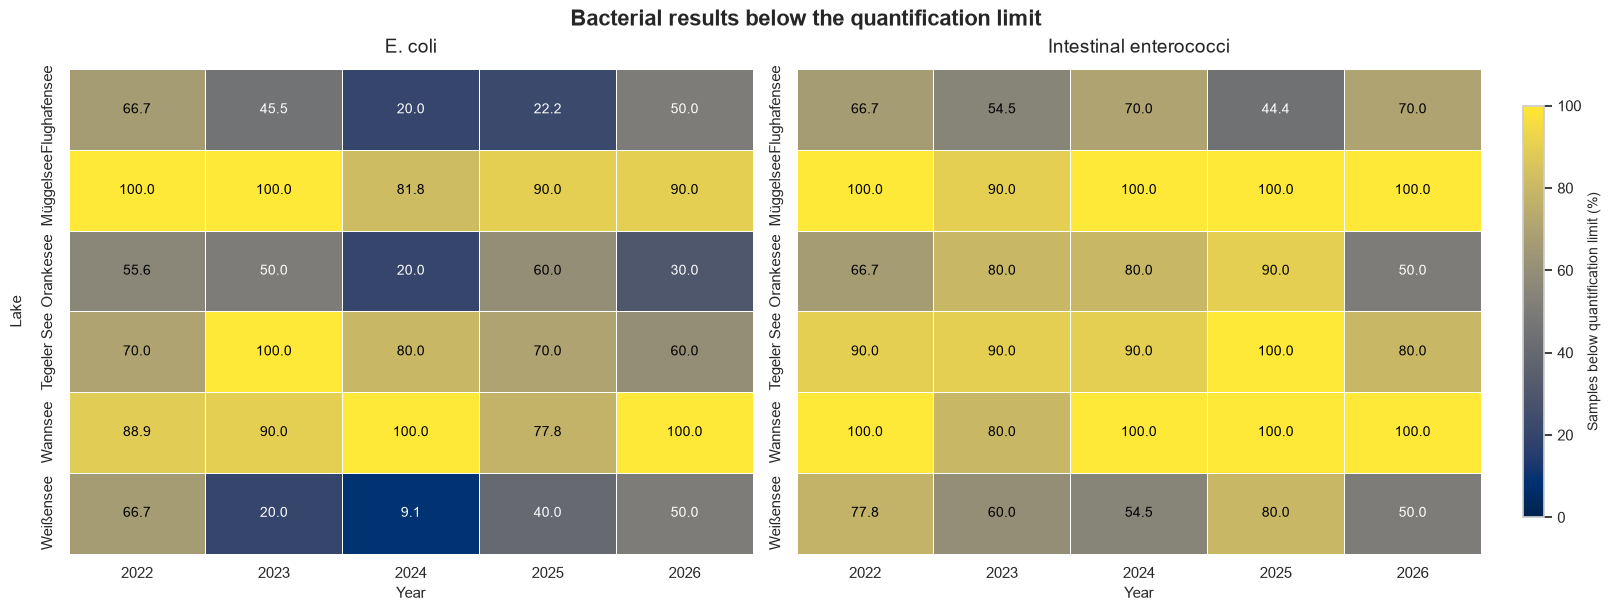

In [ ]:
#PRESENTATION-READY BACTERIAL HEATMAPS

# Create the figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    constrained_layout=True
)

cmap = "cividis"

# Draw E. coli heatmap
sns.heatmap(
    e_coli_heatmap,
    annot=True,
    fmt=".1f",
    cmap=cmap,
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar=False,
    annot_kws={"fontsize": 10},
    ax=axes[0]
)

axes[0].set_title("E. coli", fontsize=14, pad=12)
axes[0].set_xlabel("Year", fontsize=11)
axes[0].set_ylabel("Lake", fontsize=11, labelpad=12)

# Draw enterococci heatmap
sns.heatmap(
    enterococci_heatmap,
    annot=True,
    fmt=".1f",
    cmap=cmap,
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar=False,
    annot_kws={"fontsize": 10},
    ax=axes[1]
)

axes[1].set_title("Intestinal enterococci", fontsize=14, pad=12)
axes[1].set_xlabel("Year", fontsize=11)
axes[1].set_ylabel("")

# Adjust annotation text contrast using cell brightness
for ax in axes:
    for text in ax.texts:
        value = float(text.get_text())

        # Get the background colour corresponding to the value
        background = plt.get_cmap(cmap)(value / 100)

        # Calculate relative brightness
        brightness = (
            0.2126 * background[0]
            + 0.7152 * background[1]
            + 0.0722 * background[2]
        )

        # Use white text on dark cells and black on light cells
        text.set_color("black" if brightness > 0.5 else "white")

# Add one shared colour bar
colorbar = fig.colorbar(
    axes[0].collections[0],
    ax=axes,
    location="right",
    shrink=0.85,
    pad=0.03
)

colorbar.set_label(
    "Samples below quantification limit (%)",
    fontsize=10
)

# Add an overall title
fig.suptitle(
    "Bacterial results below the quantification limit",
    fontsize=16,
    fontweight="bold"
)

# Save the presentation-quality figure
plt.savefig(
    "water_quality_bacterial_below_limit_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The heatmaps show the proportion of bacterial samples reported below the quantification limit (15 KBE/100 ml) across six Berlin lakes and five years. They highlight differences between lakes and years, helping identify patterns for further investigation using the actual reported bacterial concentrations.

In [ ]:
#PREPARE REPORTED BACTERIAL CONCENTRATIONS

# Keep only unqualified results without a null prefix
e_coli_values = water_quality[
    water_quality["e_coli_result_type"] == "unqualified — no null prefix"
].copy()

enterococci_values = water_quality[
    water_quality["intestinal_enterococci_result_type"] == "unqualified — no null prefix"
].copy()

# Display the number of observations available
print("E. coli observations:", len(e_coli_values))
print("Enterococci observations:", len(enterococci_values))

# Check the numeric values
print("\nE. coli summary:")
display(e_coli_values["e_coli_numeric"].describe())

print("\nEnterococci summary:")
display(enterococci_values["intestinal_enterococci_numeric"].describe())

E. coli observations: 91
Enterococci observations: 53

E. coli summary:


count     91.00
mean     140.03
std      491.52
min        0.00
25%       15.00
50%       30.00
75%       61.00
max     4277.00
Name: e_coli_numeric, dtype: float64


Enterococci summary:


count     53.00
mean     118.25
std      558.46
min        0.00
25%       15.00
50%       15.00
75%       30.00
max     4005.00
Name: intestinal_enterococci_numeric, dtype: float64

In [ ]:
#INVESTIGATE ZERO VALUES AND EXTREMES

# Check zero-value records
print("E. coli zero values:")
display(
    e_coli_values.loc[
        e_coli_values["e_coli_numeric"] == 0,
        ["date", "lake", "e_coli_raw", "e_coli_numeric"]
    ]
)

print("\nEnterococci zero values:")
display(
    enterococci_values.loc[
        enterococci_values["intestinal_enterococci_numeric"] == 0,
        ["date", "lake", "intestinal_enterococci_raw",
         "intestinal_enterococci_numeric"]
    ]
)

# Inspect the ten highest reported values
print("\nHighest E. coli values:")
display(
    e_coli_values.nlargest(10, "e_coli_numeric")[
        ["date", "lake", "e_coli_raw", "e_coli_numeric"]
    ]
)

print("\nHighest enterococci values:")
display(
    enterococci_values.nlargest(10, "intestinal_enterococci_numeric")[
        ["date", "lake", "intestinal_enterococci_raw",
         "intestinal_enterococci_numeric"]
    ]
)

E. coli zero values:


,date,lake,e_coli_raw,e_coli_numeric
197,2026-09-07,Tegeler See,"0,0000",0.00



Enterococci zero values:


,date,lake,intestinal_enterococci_raw,intestinal_enterococci_numeric
197,2026-09-07,Tegeler See,"0,0000",0.00



Highest E. coli values:


,date,lake,e_coli_raw,e_coli_numeric
76,2024-08-07,Müggelsee,"4277,00",4277.00
276,2024-09-09,Weißensee,"1561,00",1561.00
151,2022-06-01,Tegeler See,"1100,00",1100.00
42,2026-06-24,Flughafensee,740,740.00
13,2023-06-28,Flughafensee,"606,00",606.00
261,2023-06-28,Weißensee,"539,00",539.00
145,2026-08-05,Orankesee,251,251.00
17,2023-08-10,Flughafensee,"213,00",213.00
16,2023-07-26,Flughafensee,"197,00",197.00
272,2024-07-17,Weißensee,"161,00",161.00



Highest enterococci values:


,date,lake,intestinal_enterococci_raw,intestinal_enterococci_numeric
151,2022-06-01,Tegeler See,"4005,00",4005.00
276,2024-09-09,Weißensee,"918,00",918.00
29,2024-09-09,Flughafensee,"144,00",144.00
13,2023-06-28,Flughafensee,"127,00",127.00
42,2026-06-24,Flughafensee,109,109.00
262,2023-07-13,Weißensee,"77,00",77.00
16,2023-07-26,Flughafensee,"61,00",61.00
12,2023-06-15,Flughafensee,"46,00",46.00
14,2023-07-05,Flughafensee,"30,00",30.00
112,2023-06-15,Orankesee,"30,00",30.00


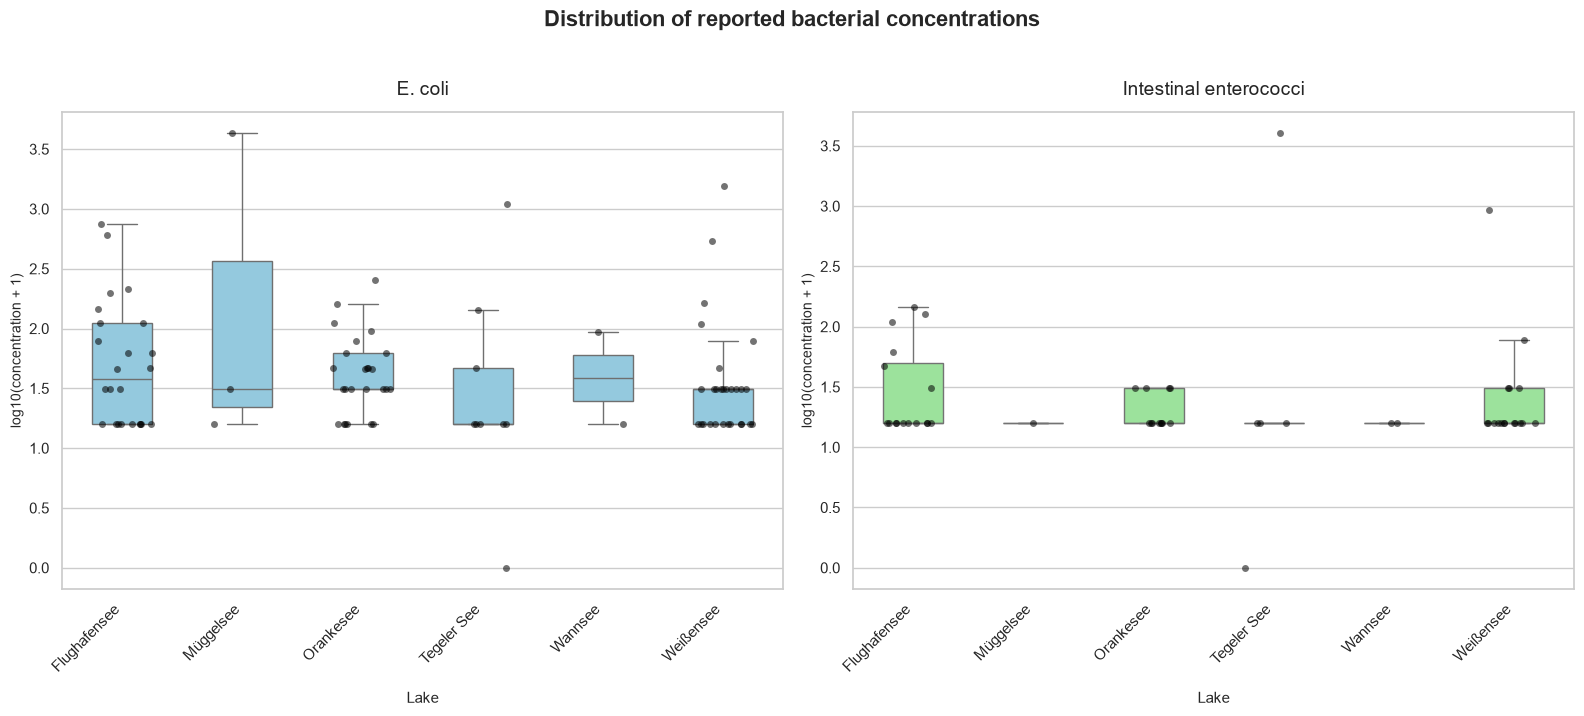

In [ ]:
#BACTERIAL DISTRIBUTION PLOTS

# Create the figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

# E. coli boxplot
sns.boxplot(
    data=e_coli_values,
    x="lake",
    y="e_coli_log",
    color="skyblue",
    showfliers=False,
    width=0.5,
    ax=axes[0]
)

# Add individual observations
sns.stripplot(
    data=e_coli_values,
    x="lake",
    y="e_coli_log",
    color="black",
    alpha=0.55,
    jitter=0.25,
    size=5,
    ax=axes[0]
)

axes[0].set_title("E. coli", fontsize=14, pad=12)
axes[0].set_xlabel("Lake", fontsize=11, labelpad=12)
axes[0].set_ylabel("log10(concentration + 1)", fontsize=10)

# Enterococci boxplot
sns.boxplot(
    data=enterococci_values,
    x="lake",
    y="enterococci_log",
    color="lightgreen",
    showfliers=False,
    width=0.5,
    ax=axes[1]
)

# Add individual observations
sns.stripplot(
    data=enterococci_values,
    x="lake",
    y="enterococci_log",
    color="black",
    alpha=0.55,
    jitter=0.25,
    size=5,
    ax=axes[1]
)

axes[1].set_title("Intestinal enterococci", fontsize=14, pad=12)
axes[1].set_xlabel("Lake", fontsize=11, labelpad=12)
axes[1].set_ylabel("log10(concentration + 1)", fontsize=10)

# Standardise lake label formatting
for ax in axes:
    ax.tick_params(axis="x", labelrotation=45)

    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

# Overall title
fig.suptitle(
    "Distribution of reported bacterial concentrations",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

# Adjust spacing
plt.tight_layout()

# Save at presentation quality
plt.savefig(
    "bacterial_concentration_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

E. coli distribution
- Müggelsee recorded the highest reported E. coli concentration (4,277 KBE/100 ml), despite a considerably lower median.
- This suggests substantial variability, with a small number of high observations influencing the distribution.
- Other lakes also show elevated individual measurements, including Weißensee and Tegeler See.
Intestinal enterococci distribution
- Most quantifiable observations are concentrated near the lower end of the plotted scale.
- Tegeler See recorded the highest value (4,005 KBE/100 ml), followed by Weißensee (918 KBE/100 ml).
- These isolated high observations warrant further investigation, but cannot independently establish contamination events.

In [ ]:
#CHECK PAIRED TEMPERATURE AND BACTERIAL DATA

# Identify records with usable water temperature
valid_temperature = (
    water_quality["water_temperature_numeric"].notna()
    & ~water_quality["temperature_zero_flag"].fillna(False)
)

# Identify unqualified bacterial results without null prefixes
valid_e_coli = (
    water_quality["e_coli_result_type"]
    == "unqualified — no null prefix"
)

valid_enterococci = (
    water_quality["intestinal_enterococci_result_type"]
    == "unqualified — no null prefix"
)

# Create paired datasets
temperature_e_coli = water_quality[
    valid_temperature & valid_e_coli
].copy()

temperature_enterococci = water_quality[
    valid_temperature & valid_enterococci
].copy()

# Display paired observation counts
print("Paired water temperature and E. coli observations:",
      len(temperature_e_coli))

print("Paired water temperature and enterococci observations:",
      len(temperature_enterococci))

# Compare availability by lake
paired_counts = pd.DataFrame({
    "E. coli": temperature_e_coli.groupby("lake").size(),
    "Enterococci": temperature_enterococci.groupby("lake").size()
}).fillna(0).astype(int)

print("\nPaired observations by lake:")
display(paired_counts)

# Inspect the paired measurements
print("\nE. coli paired data:")
display(
    temperature_e_coli[
        ["date", "lake", "water_temperature_numeric", "e_coli_numeric"]
    ].head(10)
)

print("\nEnterococci paired data:")
display(
    temperature_enterococci[
        ["date", "lake", "water_temperature_numeric",
         "intestinal_enterococci_numeric"]
    ].head(10)
)

Paired water temperature and E. coli observations: 25
Paired water temperature and enterococci observations: 16

Paired observations by lake:


,E. coli,Enterococci
lake,,
Flughafensee,7,5
Müggelsee,1,0
Orankesee,7,4
Tegeler See,3,1
Weißensee,7,6



E. coli paired data:


,date,lake,water_temperature_numeric,e_coli_numeric
32,2025-05-26,Flughafensee,17.70,30.00
38,2025-09-03,Flughafensee,21.30,15.00
41,2026-06-10,Flughafensee,21.00,15.00
42,2026-06-24,Flughafensee,25.30,740.00
43,2026-07-08,Flughafensee,21.20,61.00
46,2026-08-19,Flughafensee,22.10,15.00
48,2026-09-09,Flughafensee,19.90,30.00
96,2026-08-04,Müggelsee,22.80,15.00
138,2025-09-03,Orankesee,21.60,30.00
139,2026-05-06,Orankesee,17.30,61.00



Enterococci paired data:


,date,lake,water_temperature_numeric,intestinal_enterococci_numeric
32,2025-05-26,Flughafensee,17.70,15.00
38,2025-09-03,Flughafensee,21.30,15.00
40,2026-05-26,Flughafensee,21.60,15.00
42,2026-06-24,Flughafensee,25.30,109.00
47,2026-09-01,Flughafensee,21.00,15.00
141,2026-06-10,Orankesee,21.20,15.00
145,2026-08-05,Orankesee,25.20,30.00
147,2026-09-02,Orankesee,20.40,15.00
148,2026-09-09,Orankesee,19.80,15.00
189,2026-04-27,Tegeler See,13.10,15.00


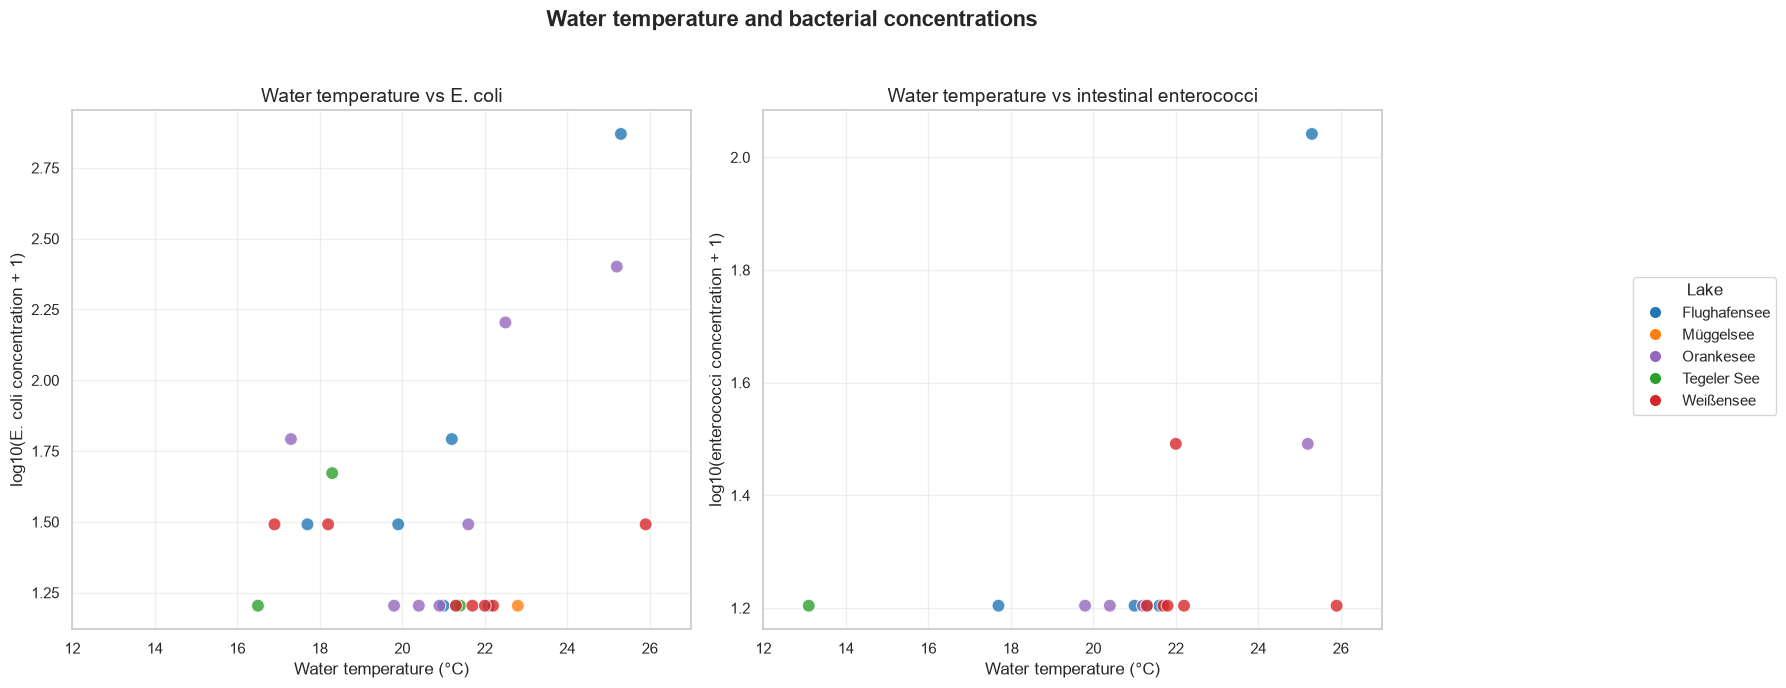

In [ ]:
#PRESENTATION-READY TEMPERATURE SCATTERPLOTS

from matplotlib.lines import Line2D

# Define consistent lake colours across both charts
lake_order = [
    "Flughafensee",
    "Müggelsee",
    "Orankesee",
    "Tegeler See",
    "Weißensee"
]

lake_palette = {
    "Flughafensee": "tab:blue",
    "Müggelsee": "tab:orange",
    "Orankesee": "tab:purple",
    "Tegeler See": "tab:green",
    "Weißensee": "tab:red"
}

# Create side-by-side charts
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

# E. coli scatterplot
sns.scatterplot(
    data=temperature_e_coli,
    x="water_temperature_numeric",
    y="e_coli_log",
    hue="lake",
    hue_order=lake_order,
    palette=lake_palette,
    s=85,
    alpha=0.8,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Water temperature vs E. coli", fontsize=14)
axes[0].set_xlabel("Water temperature (°C)")
axes[0].set_ylabel("log10(E. coli concentration + 1)")

# Enterococci scatterplot
sns.scatterplot(
    data=temperature_enterococci,
    x="water_temperature_numeric",
    y="enterococci_log",
    hue="lake",
    hue_order=lake_order,
    palette=lake_palette,
    s=85,
    alpha=0.8,
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    "Water temperature vs intestinal enterococci",
    fontsize=14
)
axes[1].set_xlabel("Water temperature (°C)")
axes[1].set_ylabel("log10(enterococci concentration + 1)")

# Align temperature axes
for ax in axes:
    ax.set_xlim(12, 27)
    ax.grid(alpha=0.3)

# Create one shared legend
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=lake_palette[lake],
        markersize=9,
        label=lake
    )
    for lake in lake_order
]

fig.legend(
    handles=legend_handles,
    title="Lake",
    loc="center right",
    bbox_to_anchor=(1.12, 0.5)
)

# Overall title
fig.suptitle(
    "Water temperature and bacterial concentrations",
    fontsize=16,
    fontweight="bold"
)

# Adjust layout and save
plt.tight_layout(rect=[0, 0, 0.88, 0.95])

plt.savefig(
    "water_temperature_bacterial_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

"The scatterplots explore the relationship between water temperature and reported bacterial concentrations across five Berlin lakes. Most observations are concentrated at the lower end of the bacterial concentration scale, while a small number of higher values occur at warmer temperatures. These observations suggest a possible positive association, particularly at higher temperatures, but the limited number of paired measurements prevents us from establishing a consistent relationship

In [ ]:
#CORRELATION: WATER TEMPERATURE VS BACTERIA

from scipy.stats import spearmanr, pearsonr

# Define the variables for each bacterial indicator
correlation_datasets = {
    "E. coli": (
        temperature_e_coli,
        "e_coli_numeric",
        "e_coli_log"
    ),
    "Intestinal enterococci": (
        temperature_enterococci,
        "intestinal_enterococci_numeric",
        "enterococci_log"
    )
}

# Calculate correlations
correlation_results = []

for indicator, (df, concentration_col, log_col) in correlation_datasets.items():

    # Spearman correlation using original concentrations
    spearman_rho, spearman_p = spearmanr(
        df["water_temperature_numeric"],
        df[concentration_col]
    )

    # Pearson correlation using log-transformed concentrations
    pearson_r, pearson_p = pearsonr(
        df["water_temperature_numeric"],
        df[log_col]
    )

    correlation_results.append({
        "indicator": indicator,
        "n": len(df),
        "spearman_rho": spearman_rho,
        "spearman_p_value": spearman_p,
        "pearson_r_log": pearson_r,
        "pearson_p_value": pearson_p
    })

# Display results
correlation_table = pd.DataFrame(correlation_results)

display(correlation_table.round(4))

,indicator,n,spearman_rho,spearman_p_value,pearson_r_log,pearson_p_value
0,E. coli,25,0.06,0.77,0.35,0.08
1,Intestinal enterococci,16,0.54,0.03,0.46,0.08


In [ ]:
#INSPECT ENTEROCOCCI OBSERVATIONS BY LAKE

# Summarise paired observations for each lake
enterococci_by_lake = (
    temperature_enterococci
    .groupby("lake")
    .agg(
        observations=("intestinal_enterococci_numeric", "count"),
        mean_temperature=("water_temperature_numeric", "mean"),
        min_temperature=("water_temperature_numeric", "min"),
        max_temperature=("water_temperature_numeric", "max"),
        median_enterococci=("intestinal_enterococci_numeric", "median"),
        max_enterococci=("intestinal_enterococci_numeric", "max")
    )
    .reset_index()
)

display(enterococci_by_lake.round(2))

# Inspect individual paired observations
enterococci_observations = (
    temperature_enterococci[
        [
            "date",
            "lake",
            "water_temperature_numeric",
            "intestinal_enterococci_numeric"
        ]
    ]
    .sort_values(
        ["lake", "water_temperature_numeric"]
    )
    .reset_index(drop=True)
)

display(enterococci_observations)

,lake,observations,mean_temperature,min_temperature,max_temperature,median_enterococci,max_enterococci
0,Flughafensee,5,21.38,17.70,25.30,15.00,109.00
1,Orankesee,4,21.65,19.80,25.20,15.00,30.00
2,Tegeler See,1,13.10,13.10,13.10,15.00,15.00
3,Weißensee,6,22.48,21.30,25.90,15.00,30.00


,date,lake,water_temperature_numeric,intestinal_enterococci_numeric
0,2025-05-26,Flughafensee,17.70,15.00
1,2026-09-01,Flughafensee,21.00,15.00
2,2025-09-03,Flughafensee,21.30,15.00
3,2026-05-26,Flughafensee,21.60,15.00
4,2026-06-24,Flughafensee,25.30,109.00
5,2026-09-09,Orankesee,19.80,15.00
6,2026-09-02,Orankesee,20.40,15.00
7,2026-06-10,Orankesee,21.20,15.00
8,2026-08-05,Orankesee,25.20,30.00
9,2026-04-27,Tegeler See,13.10,15.00


In [ ]:
#SENSITIVITY CHECK: HIGHEST ENTEROCOCCI VALUE

from scipy.stats import spearmanr

# Calculate the original correlation
original_rho, original_p = spearmanr(
    temperature_enterococci["water_temperature_numeric"],
    temperature_enterococci["intestinal_enterococci_numeric"]
)

# Identify the observation with the highest enterococci concentration
highest_index = temperature_enterococci[
    "intestinal_enterococci_numeric"
].idxmax()

highest_observation = temperature_enterococci.loc[highest_index]

# Create a dataset without that single observation
enterococci_without_max = temperature_enterococci.drop(
    index=highest_index
)

# Recalculate the correlation
revised_rho, revised_p = spearmanr(
    enterococci_without_max["water_temperature_numeric"],
    enterococci_without_max["intestinal_enterococci_numeric"]
)

# Display comparison
sensitivity_results = pd.DataFrame({
    "analysis": [
        "All observations",
        "Excluding highest observation"
    ],
    "n": [
        len(temperature_enterococci),
        len(enterococci_without_max)
    ],
    "spearman_rho": [
        original_rho,
        revised_rho
    ],
    "p_value": [
        original_p,
        revised_p
    ]
})

display(sensitivity_results.round(4))

print("\nHighest observation:")
display(
    highest_observation[
        [
            "date",
            "lake",
            "water_temperature_numeric",
            "intestinal_enterococci_numeric"
        ]
    ].to_frame().T
)

,analysis,n,spearman_rho,p_value
0,All observations,16,0.54,0.03
1,Excluding highest observation,15,0.45,0.09



Highest observation:


,date,lake,water_temperature_numeric,intestinal_enterococci_numeric
42,2026-06-24 00:00:00,Flughafensee,25.30,109.00


A moderate positive association was observed between water temperature and intestinal enterococci concentrations (Spearman ρ = 0.54, n = 16, p = 0.03). However, a sensitivity analysis excluding the highest observation reduced the correlation to ρ = 0.45 (n = 15, p = 0.09). This suggests that the observed relationship is partly influenced by an elevated measurement at Flughafensee. Given the small sample size and differences between lakes, the results should be interpreted as exploratory rather than evidence of a general temperature-related increase in bacterial concentrations.

#### Air temperature vs E. coli

Using weather data vs bacteria sample quantity as water temperature data was mostly missing for period 2022-2024

In [ ]:
#LOAD AND INSPECT WEATHER DATA

weather = pd.read_csv(
    data_folder / "df_weather_combined_2022_2026.csv",
    parse_dates=["date"]
)

# Inspect dimensions and columns
print("Shape:", weather.shape)

print("\nColumns:")
print(weather.columns.tolist())

print("\nData types:")
print(weather.dtypes)

# Inspect date coverage
print("\nDate range:")
print("Start:", weather["date"].min())
print("End:", weather["date"].max())

# Inspect sample records
display(weather.head())

Shape: (14822, 13)

Columns:
['station_id', 'date', 'tavg', 'tmin', 'tmax', 'prcp', 'wspd', 'tsun', 'cloud_cover', 'pres_dwd', 'station', 'source', 'pres_meteostat']

Data types:
station_id               float64
date              datetime64[us]
tavg                     float64
tmin                     float64
tmax                     float64
prcp                     float64
wspd                     float64
tsun                     float64
cloud_cover              float64
pres_dwd                 float64
station                      str
source                       str
pres_meteostat           float64
dtype: object

Date range:
Start: 2022-01-01 00:00:00
End: 2026-10-30 00:00:00


,station_id,date,tavg,tmin,tmax,prcp,wspd,tsun,cloud_cover,pres_dwd,station,source,pres_meteostat
0,NaN,2022-01-01,11.20,9.50,11.70,1.70,16.40,NaN,NaN,NaN,Alexanderplatz,Meteostat,1021.30
1,NaN,2022-01-02,9.50,8.10,10.90,2.00,17.70,NaN,NaN,NaN,Alexanderplatz,Meteostat,1013.00
2,NaN,2022-01-03,8.70,7.00,10.00,4.00,20.20,NaN,NaN,NaN,Alexanderplatz,Meteostat,1006.50
3,NaN,2022-01-04,6.80,5.40,7.70,3.00,12.10,NaN,NaN,NaN,Alexanderplatz,Meteostat,996.80
4,NaN,2022-01-05,3.70,3.00,4.90,2.30,18.80,NaN,NaN,NaN,Alexanderplatz,Meteostat,997.80


In [ ]:
#WEATHER STATION COVERAGE

# Summarise observations by station and source
station_summary = (
    weather
    .groupby(["station", "source"])
    .agg(
        observations=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        available_tmax=("tmax", "count"),
        available_tavg=("tavg", "count")
    )
    .reset_index()
)

display(station_summary)

# Check duplicate station-date combinations
duplicate_station_dates = weather.duplicated(
    subset=["station", "date"]
).sum()

print("\nDuplicate station-date combinations:", duplicate_station_dates)

# Check missing temperature values
print("\nMissing temperature values:")
print(
    weather[["tavg", "tmin", "tmax"]]
    .isna()
    .sum()
)

,station,source,observations,first_date,last_date,available_tmax,available_tavg
0,Alexanderplatz,Meteostat,1764,2022-01-01,2026-10-30,1752,1752
1,Berlin Brandenburg,DWD,1744,2022-01-01,2026-10-10,1744,1744
2,Buch,DWD,1744,2022-01-01,2026-10-10,1744,1744
3,Dahlem,DWD,1730,2022-01-01,2026-10-10,1728,1728
4,Dahlem,Meteostat,1399,2022-01-01,2026-10-30,1399,1399
5,Marzahn,DWD,1231,2022-01-01,2026-10-10,1224,1224
6,Marzahn,Meteostat,1399,2022-01-01,2026-10-30,1378,1380
7,Tegel,Meteostat,1764,2022-01-01,2026-10-30,1764,1764
8,Tempelhof,DWD,1744,2022-01-01,2026-10-10,1743,1744
9,Tempelhof,Meteostat,303,2026-01-01,2026-10-30,303,303



Duplicate station-date combinations: 2528

Missing temperature values:
tavg    40
tmin    43
tmax    43
dtype: int64


In [ ]:
#INVESTIGATE DUPLICATE RECORDS

# Check duplicates using station, date and source
duplicate_station_date_source = weather.duplicated(
    subset=["station", "date", "source"]
).sum()

print(
    "Duplicate station-date-source combinations:",
    duplicate_station_date_source
)

# Count how many sources report each station on the same date
source_overlap = (
    weather
    .groupby(["station", "date"])["source"]
    .nunique()
    .reset_index(name="number_of_sources")
)

print("\nStation-date combinations reported by multiple sources:")
print(
    source_overlap["number_of_sources"]
    .value_counts()
    .sort_index()
)

# Inspect station locations with multiple sources
display(
    source_overlap[
        source_overlap["number_of_sources"] > 1
    ].groupby("station")
    .size()
    .rename("overlapping_dates")
    .reset_index()
)

Duplicate station-date-source combinations: 0

Station-date combinations reported by multiple sources:
number_of_sources
1    9766
2    2528
Name: count, dtype: int64


,station,overlapping_dates
0,Dahlem,1379
1,Marzahn,866
2,Tempelhof,283


In [ ]:
#COMPARE DWD AND METEOSTAT

# Separate the two sources
dwd = weather[weather["source"] == "DWD"].copy()
meteostat = weather[weather["source"] == "Meteostat"].copy()

# Match observations from the same station and date
weather_comparison = dwd.merge(
    meteostat,
    on=["station", "date"],
    suffixes=("_dwd", "_meteostat")
)

# Compare temperature measurements
for variable in ["tmax", "tavg", "tmin"]:

    # Keep only pairs where both sources have a value
    paired = weather_comparison[
        [f"{variable}_dwd", f"{variable}_meteostat"]
    ].dropna()

    # Calculate differences
    differences = (
        paired[f"{variable}_dwd"]
        - paired[f"{variable}_meteostat"]
    )

    print(f"\n{variable.upper()}")
    print("Paired observations:", len(paired))
    print("Mean absolute difference:", differences.abs().mean().round(2))
    print("Median absolute difference:", differences.abs().median().round(2))
    print("Maximum absolute difference:", differences.abs().max().round(2))
    print("Correlation:", paired.corr().iloc[0, 1].round(3))


TMAX
Paired observations: 2527
Mean absolute difference: 0.0
Median absolute difference: 0.0
Maximum absolute difference: 0.0
Correlation: 1.0

TAVG
Paired observations: 2528
Mean absolute difference: 0.0
Median absolute difference: 0.0
Maximum absolute difference: 0.0
Correlation: 1.0

TMIN
Paired observations: 2527
Mean absolute difference: 0.0
Median absolute difference: 0.0
Maximum absolute difference: 0.0
Correlation: 1.0


In [ ]:
#CREATE DAILY BERLIN WEATHER DATA

# Remove duplicate source records for the same station and date
weather_unique = weather.drop_duplicates(
    subset=["station", "date"]
).copy()

# Calculate daily averages across available stations
weather_daily = (
    weather_unique
    .groupby("date")
    .agg(
        tavg=("tavg", "mean"),
        tmin=("tmin", "mean"),
        tmax=("tmax", "mean"),
        prcp=("prcp", "mean"),
        wspd=("wspd", "mean"),
        tsun=("tsun", "mean"),
        cloud_cover=("cloud_cover", "mean"),
        stations_available=("station", "nunique")
    )
    .reset_index()
)

# Inspect the resulting dataset
print("Shape:", weather_daily.shape)

print("\nDate range:")
print("Start:", weather_daily["date"].min())
print("End:", weather_daily["date"].max())

print("\nNumber of stations contributing to each daily average:")
display(
    weather_daily["stations_available"]
    .value_counts()
    .sort_index()
    .rename("days")
    .to_frame()
)

print("\nDaily weather sample:")
display(weather_daily.head())

Shape: (1764, 9)

Date range:
Start: 2022-01-01 00:00:00
End: 2026-10-30 00:00:00

Number of stations contributing to each daily average:


,days
stations_available,
5,20
6,14
7,1730



Daily weather sample:


,date,tavg,tmin,tmax,prcp,wspd,tsun,cloud_cover,stations_available
0,2022-01-01,11.67,9.89,12.43,0.44,17.09,NaN,NaN,7
1,2022-01-02,9.77,7.91,11.51,4.34,17.61,NaN,NaN,7
2,2022-01-03,8.79,6.24,10.44,2.39,22.14,NaN,NaN,7
3,2022-01-04,6.36,4.21,7.30,2.04,12.17,NaN,NaN,7
4,2022-01-05,3.69,2.59,4.86,1.14,20.45,NaN,NaN,7


In [ ]:
#MATCH WEATHER TO WATER QUALITY

# Merge daily weather conditions with each lake sampling record
water_weather = water_quality.merge(
    weather_daily,
    on="date",
    how="left",
    validate="many_to_one"
)

# Check matching coverage
print("Water-quality records:", len(water_quality))
print("Matched weather records:", water_weather["tmax"].notna().sum())
print("Unmatched weather records:", water_weather["tmax"].isna().sum())

print(
    "\nPercentage with matched weather:",
    round(water_weather["tmax"].notna().mean() * 100, 2),
    "%"
)

# Check coverage by year
yearly_coverage = (
    water_weather
    .assign(year=water_weather["date"].dt.year)
    .groupby("year")
    .agg(
        water_samples=("date", "count"),
        weather_matched=("tmax", "count")
    )
    .reset_index()
)

yearly_coverage["match_pct"] = (
    yearly_coverage["weather_matched"]
    / yearly_coverage["water_samples"]
    * 100
)

display(yearly_coverage)

# Inspect matched records
display(
    water_weather[
        ["date", "lake", "water_temperature_numeric",
         "e_coli_numeric", "intestinal_enterococci_numeric",
         "tavg", "tmax", "tmin"]
    ].head(10)
)

Water-quality records: 298
Matched weather records: 298
Unmatched weather records: 0

Percentage with matched weather: 100.0 %


,year,water_samples,weather_matched,match_pct
0,2022,56,56,100.00
1,2023,61,61,100.00
2,2024,63,63,100.00
3,2025,58,58,100.00
4,2026,60,60,100.00


,date,lake,water_temperature_numeric,e_coli_numeric,intestinal_enterococci_numeric,tavg,tmax,tmin
0,2022-04-20,Flughafensee,NaN,15.00,15.00,9.37,13.96,5.29
1,2022-05-17,Flughafensee,NaN,15.00,15.00,16.90,21.36,12.89
2,2022-05-31,Flughafensee,NaN,15.00,15.00,14.14,19.76,7.11
3,2022-06-13,Flughafensee,NaN,15.00,15.00,16.52,21.20,12.00
4,2022-06-27,Flughafensee,NaN,15.00,15.00,27.30,34.97,19.84
5,2022-07-12,Flughafensee,NaN,15.00,15.00,19.91,26.83,11.30
6,2022-07-26,Flughafensee,NaN,15.00,15.00,19.94,24.23,16.51
7,2022-08-09,Flughafensee,NaN,45.00,15.00,21.71,27.30,16.40
8,2022-08-23,Flughafensee,NaN,15.00,15.00,20.29,25.31,16.51
9,2023-04-18,Flughafensee,NaN,15.00,15.00,8.61,13.31,4.61


In [ ]:
#SAMPLING-DAY HEAT EXPOSURE

# Classify sampling days using the existing 30°C threshold
water_weather["hot_day"] = water_weather["tmax"] >= 30

# Overall sampling-day temperature distribution
print("Sampling-day air temperature:")
display(
    water_weather[["tavg", "tmin", "tmax"]]
    .describe()
    .round(2)
)

# Count samples on hot and non-hot days
heat_summary = (
    water_weather
    .groupby("hot_day")
    .agg(
        samples=("date", "size"),
        unique_dates=("date", "nunique"),
        lakes=("lake", "nunique"),
        mean_tmax=("tmax", "mean")
    )
    .reset_index()
)

heat_summary["day_type"] = heat_summary["hot_day"].map({
    True: "Hot (≥30°C)",
    False: "Non-hot (<30°C)"
})

display(
    heat_summary[
        ["day_type", "samples", "unique_dates", "lakes", "mean_tmax"]
    ].round(2)
)

# Check hot-day sampling coverage by lake
lake_heat_summary = (
    water_weather
    .groupby(["lake", "hot_day"])
    .agg(
        samples=("date", "size"),
        unique_dates=("date", "nunique")
    )
    .reset_index()
)

display(lake_heat_summary)

Sampling-day air temperature:


,tavg,tmin,tmax
count,298.00,298.00,298.00
mean,17.82,12.40,23.11
std,4.07,3.80,4.98
min,4.50,-1.17,9.19
25%,15.59,10.79,20.13
50%,18.05,12.87,23.06
75%,20.37,14.87,26.29
max,29.23,20.09,37.71


,day_type,samples,unique_dates,lakes,mean_tmax
0,Non-hot (<30°C),279,172,6,22.45
1,Hot (≥30°C),19,12,6,32.72


,lake,hot_day,samples,unique_dates
0,Flughafensee,False,46,46
1,Flughafensee,True,3,3
2,Müggelsee,False,46,46
3,Müggelsee,True,5,5
4,Orankesee,False,47,47
5,Orankesee,True,2,2
6,Tegeler See,False,47,47
7,Tegeler See,True,3,3
8,Wannsee,False,46,46
9,Wannsee,True,3,3


In [ ]:
#BACTERIAL REPORTING CATEGORIES BY HEAT

for parameter in ["e_coli", "intestinal_enterococci"]:

    result_col = f"{parameter}_result_type"

    print(f"\n{'=' * 55}")
    print(parameter.upper())
    print("=" * 55)

    # Count observations in each reporting category
    counts = pd.crosstab(
        water_weather["hot_day"],
        water_weather[result_col]
    )

    counts.index = ["Non-hot", "Hot"]

    print("\nSample counts:")
    display(counts)

    # Calculate percentages within each heat group
    percentages = (
        pd.crosstab(
            water_weather["hot_day"],
            water_weather[result_col],
            normalize="index"
        ) * 100
    )

    percentages.index = ["Non-hot", "Hot"]

    print("\nPercentage within each heat group:")
    display(percentages.round(1))


E_COLI

Sample counts:


e_coli_result_type,below quantification limit,unqualified — no null prefix,unqualified — null prefix
Non-hot,179,82,18
Hot,10,9,0



Percentage within each heat group:


e_coli_result_type,below quantification limit,unqualified — no null prefix,unqualified — null prefix
Non-hot,64.20,29.40,6.50
Hot,52.60,47.40,0.00



INTESTINAL_ENTEROCOCCI

Sample counts:


intestinal_enterococci_result_type,below quantification limit,unqualified — no null prefix,unqualified — null prefix
Non-hot,227,47,5
Hot,13,6,0



Percentage within each heat group:


intestinal_enterococci_result_type,below quantification limit,unqualified — no null prefix,unqualified — null prefix
Non-hot,81.40,16.80,1.80
Hot,68.40,31.60,0.00


In [ ]:
#BACTERIAL CONCENTRATIONS BY HEAT

parameters = {
    "e_coli": "E. coli",
    "intestinal_enterococci": "Intestinal enterococci"
}

for parameter, label in parameters.items():

    result_col = f"{parameter}_result_type"
    value_col = f"{parameter}_numeric"

    # Keep only eligible unqualified observations
    eligible = water_weather[
        water_weather[result_col] == "unqualified — no null prefix"
    ].copy()

    # Summarise concentrations by sampling-day heat category
    summary = (
        eligible
        .groupby("hot_day")[value_col]
        .agg(
            n="count",
            median="median",
            mean="mean",
            maximum="max"
        )
        .reset_index()
    )

    # Count observations exactly at the quantification limit
    at_limit = (
        eligible
        .groupby("hot_day")[value_col]
        .apply(lambda values: (values == 15).sum())
        .rename("values_equal_to_15")
        .reset_index()
    )

    summary = summary.merge(at_limit, on="hot_day")

    summary["day_type"] = summary["hot_day"].map({
        False: "Non-hot",
        True: "Hot"
    })

    print(f"\n{label}")
    display(
        summary[
            ["day_type", "n", "median", "mean", "maximum",
             "values_equal_to_15"]
        ].round(2)
    )


E. coli


,day_type,n,median,mean,maximum,values_equal_to_15
0,Non-hot,82,30.00,141.30,4277.00,31
1,Hot,9,30.00,128.44,740.00,3



Intestinal enterococci


,day_type,n,median,mean,maximum,values_equal_to_15
0,Non-hot,47,15.00,129.11,4005.00,32
1,Hot,6,15.00,33.17,109.00,4


In [ ]:
#AIR TEMPERATURE AND BACTERIAL CONCENTRATIONS

from scipy.stats import spearmanr

parameters = {
    "e_coli": "E. coli",
    "intestinal_enterococci": "Intestinal enterococci"
}

correlation_results = []

for parameter, label in parameters.items():

    result_col = f"{parameter}_result_type"
    value_col = f"{parameter}_numeric"

    # Select eligible bacterial observations
    eligible = water_weather[
        water_weather[result_col] == "unqualified — no null prefix"
    ][["tmax", value_col]].dropna()

    # Calculate Spearman correlation
    rho, p_value = spearmanr(
        eligible["tmax"],
        eligible[value_col]
    )

    correlation_results.append({
        "indicator": label,
        "n": len(eligible),
        "spearman_rho": rho,
        "p_value": p_value
    })

correlation_summary = pd.DataFrame(correlation_results)

display(correlation_summary.round(3))

,indicator,n,spearman_rho,p_value
0,E. coli,91,0.01,0.91
1,Intestinal enterococci,53,0.03,0.85


In [ ]:
#CALCULATE PRE-SAMPLING HEAT WINDOWS

# Sort daily weather observations chronologically
weather_rolling = weather_daily.sort_values("date").copy()

# Calculate rolling averages, including the sampling day
weather_rolling["tmax_3day_mean"] = (
    weather_rolling["tmax"]
    .rolling(window=3, min_periods=3)
    .mean()
)

weather_rolling["tmax_7day_mean"] = (
    weather_rolling["tmax"]
    .rolling(window=7, min_periods=7)
    .mean()
)

# Merge rolling temperature measures into water-quality records
water_weather = water_weather.merge(
    weather_rolling[
        ["date", "tmax_3day_mean", "tmax_7day_mean"]
    ],
    on="date",
    how="left",
    validate="many_to_one"
)

# Check availability
print("Available 3-day averages:",
      water_weather["tmax_3day_mean"].notna().sum())

print("Available 7-day averages:",
      water_weather["tmax_7day_mean"].notna().sum())

# Compare correlations across exposure windows
from scipy.stats import spearmanr

parameters = {
    "e_coli": "E. coli",
    "intestinal_enterococci": "Intestinal enterococci"
}

temperature_windows = {
    "Same-day tmax": "tmax",
    "3-day mean tmax": "tmax_3day_mean",
    "7-day mean tmax": "tmax_7day_mean"
}

lagged_results = []

for parameter, label in parameters.items():

    result_col = f"{parameter}_result_type"
    value_col = f"{parameter}_numeric"

    eligible = water_weather[
        water_weather[result_col] == "unqualified — no null prefix"
    ].copy()

    for window_label, temperature_col in temperature_windows.items():

        paired = eligible[
            [temperature_col, value_col]
        ].dropna()

        rho, p_value = spearmanr(
            paired[temperature_col],
            paired[value_col]
        )

        lagged_results.append({
            "indicator": label,
            "temperature_window": window_label,
            "n": len(paired),
            "spearman_rho": rho,
            "p_value": p_value
        })

lagged_summary = pd.DataFrame(lagged_results)

display(
    lagged_summary.round(3)
)

Available 3-day averages: 298
Available 7-day averages: 298


,indicator,temperature_window,n,spearman_rho,p_value
0,E. coli,Same-day tmax,91,0.01,0.91
1,E. coli,3-day mean tmax,91,0.07,0.48
2,E. coli,7-day mean tmax,91,0.03,0.75
3,Intestinal enterococci,Same-day tmax,53,0.03,0.85
4,Intestinal enterococci,3-day mean tmax,53,0.18,0.19
5,Intestinal enterococci,7-day mean tmax,53,0.27,0.05


The correlation is weak (ρ = 0.27).


It is based on only 53 eligible observations.


The p-value is reported as 0.05, right on the conventional threshold.


We have tested multiple indicators and exposure windows, which increases the chance of finding an apparently interesting result by chance.

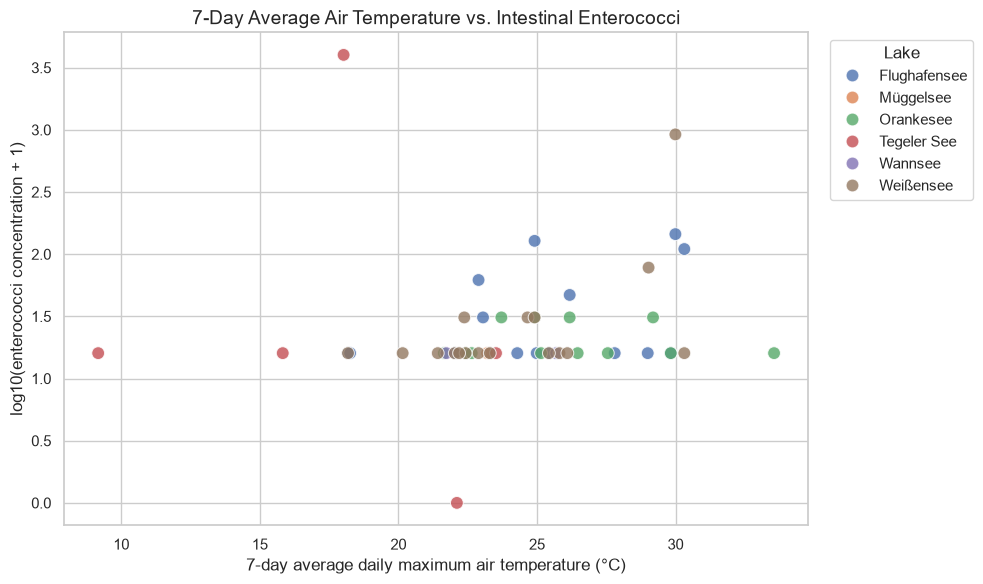


Enterococci observations above 15:


,date,lake,tmax_7day_mean,intestinal_enterococci_numeric
151,2022-06-01,Tegeler See,18.02,4005.00
276,2024-09-09,Weißensee,29.99,918.00
29,2024-09-09,Flughafensee,29.99,144.00
13,2023-06-28,Flughafensee,24.91,127.00
42,2026-06-24,Flughafensee,30.32,109.00
262,2023-07-13,Weißensee,29.03,77.00
16,2023-07-26,Flughafensee,22.89,61.00
12,2023-06-15,Flughafensee,26.18,46.00
113,2023-06-28,Orankesee,24.91,30.00
112,2023-06-15,Orankesee,26.18,30.00


In [ ]:
#VISUALISE 7-DAY HEAT AND ENTEROCOCCI

# Select eligible enterococci observations
enterococci_7day = water_weather[
    water_weather["intestinal_enterococci_result_type"]
    == "unqualified — no null prefix"
].copy()

# Transform concentrations for visualisation only
enterococci_7day["log_enterococci"] = np.log10(
    enterococci_7day["intestinal_enterococci_numeric"] + 1
)

# Create scatterplot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=enterococci_7day,
    x="tmax_7day_mean",
    y="log_enterococci",
    hue="lake",
    s=85,
    alpha=0.8
)

plt.title(
    "7-Day Average Air Temperature vs. Intestinal Enterococci",
    fontsize=14
)
plt.xlabel("7-day average daily maximum air temperature (°C)")
plt.ylabel("log10(enterococci concentration + 1)")
plt.legend(title="Lake", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Inspect observations above the quantification-limit value
print("\nEnterococci observations above 15:")
display(
    enterococci_7day[
        enterococci_7day["intestinal_enterococci_numeric"] > 15
    ][
        ["date", "lake", "tmax_7day_mean",
         "intestinal_enterococci_numeric"]
    ].sort_values("intestinal_enterococci_numeric", ascending=False)
)

##### Using seven-day average of daily maximum air temperature to represent recent heat exposure before each water-quality sampling event, reducing the influence of short-term daily temperature fluctuations. A 7-day window captures recent heat exposure. It provides a smoother measure of the preceding week's weather rather than relying on one potentially unusual day.

- No confirmed 23–25°C threshold. There are elevated observations below 23°C (including 61 at 22.89°C and 4,005 at 18.02°C). There are also many observations at or above 23°C that remain at 15. We cannot identify a contamination threshold from this scatterplot.
- Flughafensee has several elevated observations, including 127 at 24.91°C, 109 at 30.32°C and 144 at 29.99°C. This is a descriptive pattern, not proof of a continuous temperature-driven increase.
- Tegeler See has the largest outlier: 4,005 on 1 June 2022, with a 7-day average air temperature of 18.02°C. We cannot attribute it to storm overflow or another cause without additional evidence.
- Weißensee has an elevated observation of 918 at 29.99°C. This is an important observation, but it does not establish a general heat-related pattern.

In [ ]:
#SENSITIVITY ANALYSIS — ENTEROCOCCI

from scipy.stats import spearmanr

# Original eligible observations
enterococci_sensitivity = water_weather[
    water_weather["intestinal_enterococci_result_type"]
    == "unqualified — no null prefix"
].copy()

# Define alternative datasets
scenarios = {
    "All observations": enterococci_sensitivity,

    "Exclude highest observation": enterococci_sensitivity[
        enterococci_sensitivity["intestinal_enterococci_numeric"] !=
        enterococci_sensitivity["intestinal_enterococci_numeric"].max()
    ],

    "Exclude both extreme dates": enterococci_sensitivity[
        ~enterococci_sensitivity["date"].isin(
            pd.to_datetime(["2022-06-01", "2024-09-09"])
        )
    ]
}

# Calculate correlations for each scenario
sensitivity_results = []

for scenario, data in scenarios.items():

    rho, p_value = spearmanr(
        data["tmax_7day_mean"],
        data["intestinal_enterococci_numeric"]
    )

    sensitivity_results.append({
        "scenario": scenario,
        "n": len(data),
        "spearman_rho": rho,
        "p_value": p_value
    })

sensitivity_summary = pd.DataFrame(sensitivity_results)

display(sensitivity_summary.round(3))

,scenario,n,spearman_rho,p_value
0,All observations,53,0.27,0.05
1,Exclude highest observation,52,0.36,0.01
2,Exclude both extreme dates,50,0.27,0.06


Possible temperature association: The scatterplot suggests that elevated enterococci concentrations occur more frequently at higher 7-day average air temperatures. The overall Spearman correlation is weakly positive (ρ = 0.27, p = 0.05), but the data do not establish a specific temperature threshold.

Differences between lakes: Flughafensee records several elevated observations across a range of temperatures. Weißensee also records a high concentration at approximately 30°C. These patterns suggest that lake-specific conditions may matter alongside weather.

Elevated concentrations at cooler temperatures: Tegeler See records the dataset's highest observation (4,005) at a 7-day average air temperature of approximately 18°C. This shows that high concentrations are not exclusive to hot-weather conditions.

Sensitivity to extreme dates: Excluding the two dates with the highest observations reduces the correlation to ρ = 0.27 (p = 0.06). The positive direction remains, but the evidence becomes weaker.

In [ ]:
#ENTEROCOCCI AND TEMPERATURE BY LAKE

from scipy.stats import spearmanr

# Keep only exact, unqualified enterococci results
enterococci_by_lake = water_weather[
    water_weather["intestinal_enterococci_result_type"]
    == "unqualified — no null prefix"
].copy()

# Calculate descriptive statistics and Spearman correlation
lake_results = []

for lake, group in enterococci_by_lake.groupby("lake"):

    # Calculate correlation only when there are enough observations
    if len(group) >= 3:
        rho, p_value = spearmanr(
            group["tmax_7day_mean"],
            group["intestinal_enterococci_numeric"]
        )
    else:
        rho, p_value = np.nan, np.nan

    lake_results.append({
        "lake": lake,
        "n": len(group),
        "temperature_min": group["tmax_7day_mean"].min(),
        "temperature_max": group["tmax_7day_mean"].max(),
        "enterococci_min": group["intestinal_enterococci_numeric"].min(),
        "enterococci_max": group["intestinal_enterococci_numeric"].max(),
        "spearman_rho": rho,
        "p_value": p_value
    })

lake_correlation = pd.DataFrame(lake_results)

# Sort by correlation, strongest positive first
lake_correlation = lake_correlation.sort_values(
    "spearman_rho",
    ascending=False
)

display(lake_correlation.round(2))

,lake,n,temperature_min,temperature_max,enterococci_min,enterococci_max,spearman_rho,p_value
5,Weißensee,17,18.18,30.32,15.00,918.00,0.40,0.11
0,Flughafensee,16,18.18,30.32,15.00,144.00,0.31,0.25
2,Orankesee,12,21.64,33.56,15.00,30.00,0.00,1.00
3,Tegeler See,5,9.17,23.52,0.00,4005.00,-0.22,0.72
1,Müggelsee,1,23.20,23.20,15.00,15.00,NaN,NaN
4,Wannsee,2,21.73,25.69,15.00,15.00,NaN,NaN


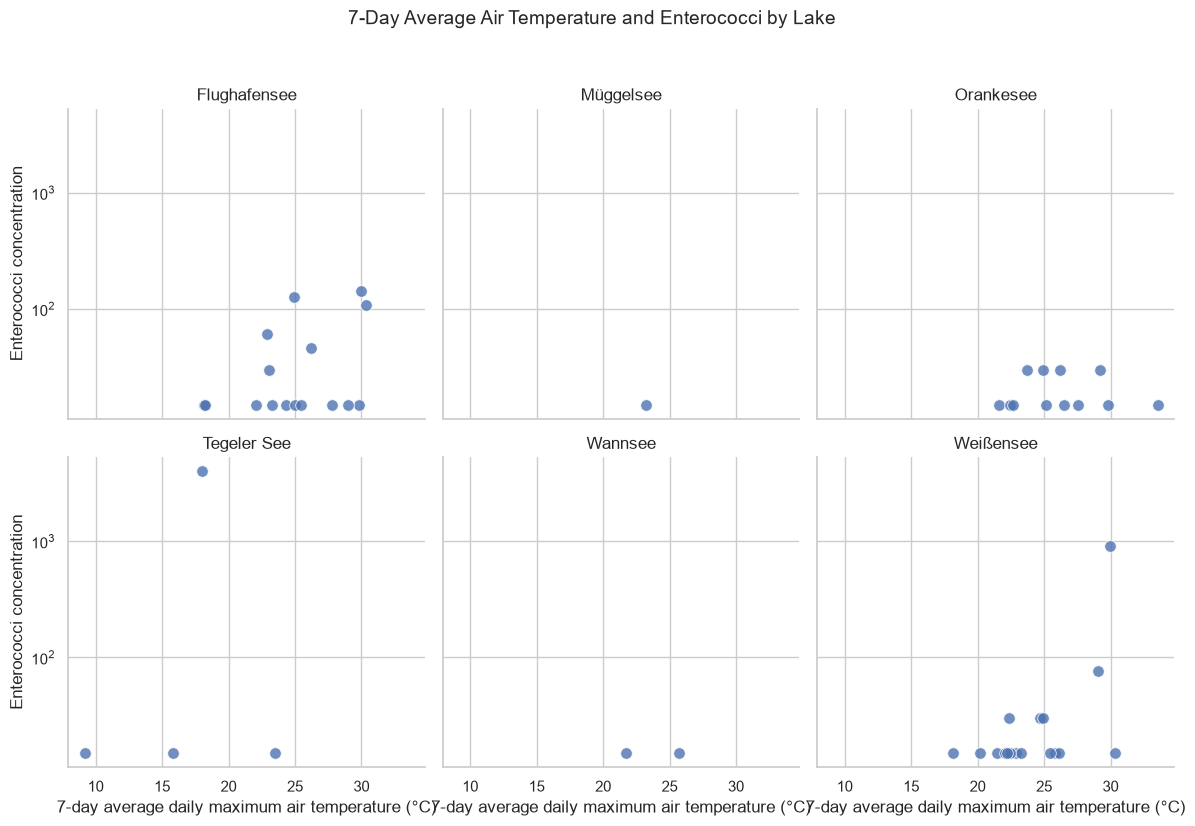

In [ ]:
#VISUALISE ENTEROCOCCI BY LAKE

# Create a separate panel for each lake
g = sns.FacetGrid(
    enterococci_by_lake,
    col="lake",
    col_wrap=3,
    height=4,
    sharex=True,
    sharey=True
)

# Plot observations
g.map_dataframe(
    sns.scatterplot,
    x="tmax_7day_mean",
    y="intestinal_enterococci_numeric",
    alpha=0.8,
    s=70
)

# Use logarithmic scale to make extreme values easier to compare
g.set(yscale="log")

# Add titles and axis labels
g.set_titles("{col_name}")
g.set_axis_labels(
    "7-day average daily maximum air temperature (°C)",
    "Enterococci concentration"
)

g.fig.suptitle(
    "7-Day Average Air Temperature and Enterococci by Lake",
    y=1.03,
    fontsize=14
)

plt.tight_layout()
plt.show()

### Visualization for Thursday's presentation

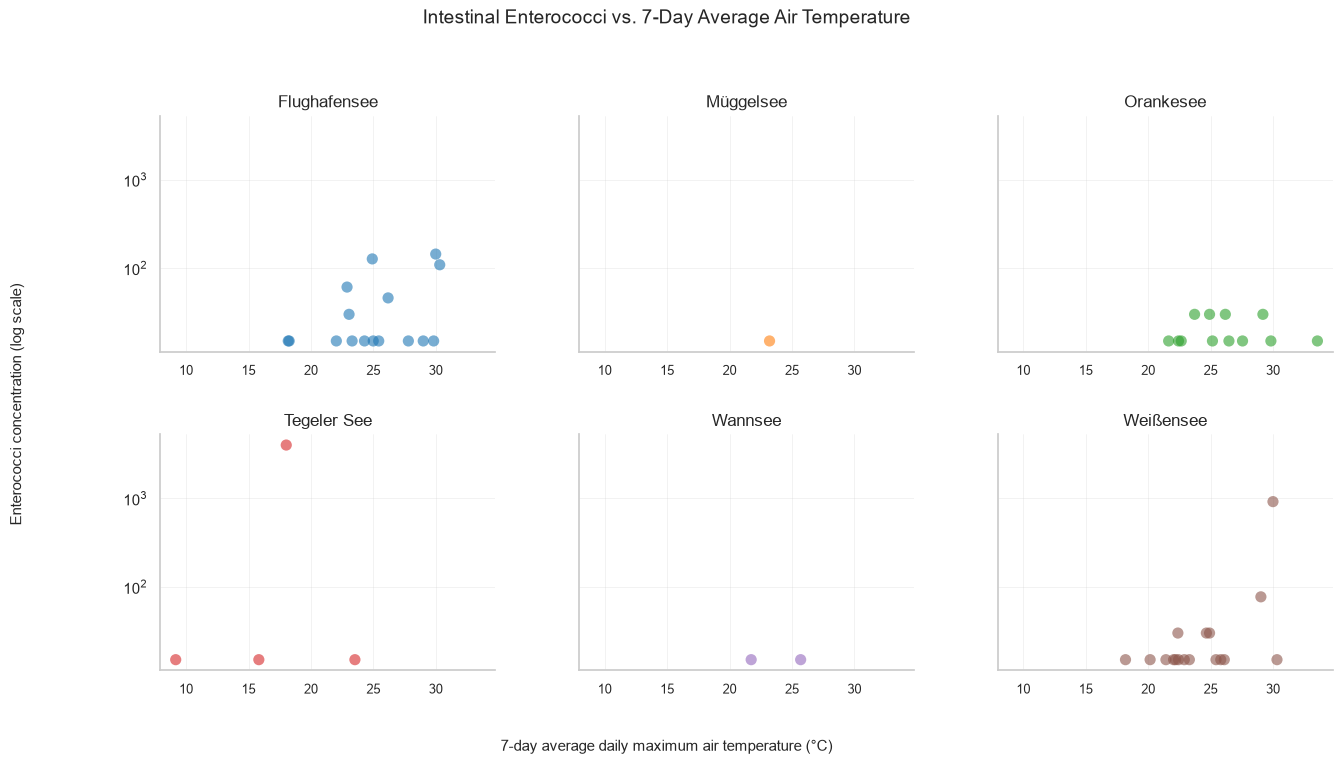

In [44]:
# Create separate panels for each lake
g = sns.FacetGrid(
    enterococci_by_lake,
    col="lake",
    col_order=lake_order,
    col_wrap=3,
    height=3.8,
    aspect=1.2,
    sharex=True,
    sharey=True
)

# Plot observations with consistent lake colours
g.map_dataframe(
    sns.scatterplot,
    x="tmax_7day_mean",
    y="intestinal_enterococci_numeric",
    hue="lake",
    palette=lake_palette,
    alpha=0.6,
    s=65,
    edgecolor="none",
    linewidth=0,
    legend=False
)

# Apply logarithmic scale
g.set(yscale="log")

# Simplify subplot titles
g.set_titles("{col_name}")

# Remove repeated axis labels
g.set_axis_labels("", "")

# Add shared title and axis labels
g.fig.suptitle(
    "Intestinal Enterococci vs. 7-Day Average Air Temperature",
    fontsize=14,
    y=1.02
)

g.fig.supxlabel(
    "7-day average daily maximum air temperature (°C)",
    fontsize=11,
    y=0.04
)

g.fig.supylabel(
    "Enterococci concentration (log scale)",
    fontsize=11,
    x=0.02
)

# Display x-axis tick labels on every panel
for ax in g.axes.flat:
    ax.tick_params(
        axis="x",
        labelbottom=True,
        labelsize=9
    )
    ax.grid(True, linewidth=0.5, alpha=0.35)

# Adjust margins and spacing
g.fig.subplots_adjust(
    top=0.88,
    bottom=0.15,
    left=0.13,
    hspace=0.35,
    wspace=0.25
)

plt.show()

### Enterococci concentrations and recent air temperature

- Flughafensee and Weißensee: Both show elevated enterococci measurements at warmer air temperatures. We cannot establish a clear threshold at 23–25°C from this chart alone.
- Tegeler See: The observation of 4,005 at approximately 18°C is a genuine extreme in the dataset. Stormwater overflow or runoff is a possible hypothesis, not a demonstrated cause.
- Müggelsee and Wannsee: Their plots contain few eligible exact measurements. We cannot conclude that they have consistently low contamination or better water quality from this filtered sample.

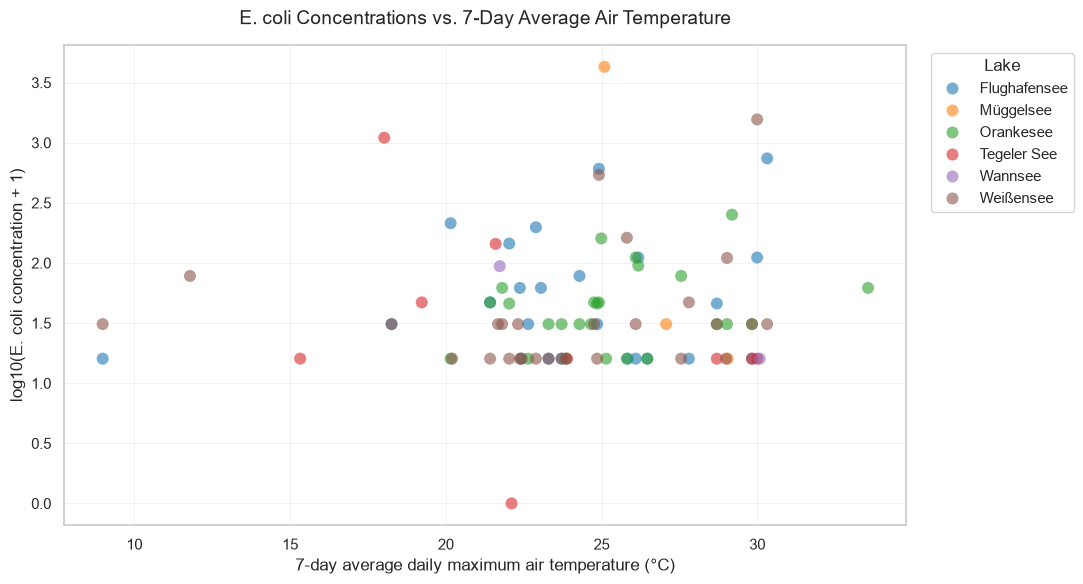

Observations with an original E. coli concentration of zero:


,date,lake,e_coli_raw,e_coli_qualifier,e_coli_numeric
197,2026-09-07,Tegeler See,"0,0000",NaN,0.00


In [42]:

# Use a more contrasting colour palette
lake_palette = dict(zip(
    lake_order,
    sns.color_palette("tab10", n_colors=6)
))

# Create scatterplot
fig, ax = plt.subplots(figsize=(11, 6))

sns.scatterplot(
    data=e_coli_plot,
    x="tmax_7day_mean",
    y="log_e_coli",
    hue="lake",
    hue_order=lake_order,
    palette=lake_palette,
    s=75,
    alpha=0.60,
    edgecolor="none",
    linewidth=0
)

# Add titles and labels
ax.set_title(
    "E. coli Concentrations vs. 7-Day Average Air Temperature",
    fontsize=14,
    pad=15
)

ax.set_xlabel("7-day average daily maximum air temperature (°C)")
ax.set_ylabel("log10(E. coli concentration + 1)")

# Improve grid readability
ax.grid(True, linewidth=0.5, alpha=0.35)
ax.set_axisbelow(True)

# Position legend outside the plot
ax.legend(
    title="Lake",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

# Inspect the zero-concentration observation
print("Observations with an original E. coli concentration of zero:")

display(
    e_coli_plot[
        e_coli_plot["e_coli_numeric"] == 0
    ][
        ["date", "lake", "e_coli_raw",
         "e_coli_qualifier", "e_coli_numeric"]
    ]
)

Warmer sampling periods: Several elevated E. coli measurements appear above 25°C. This is a visible pattern, but it does not establish a temperature-triggered increase or a threshold.

Müggelsee: The highest visible peak is worth highlighting, but it is an individual observation, not evidence of a consistent lake-wide response.

Tegeler See: The elevated observation around 18°C shows that high concentrations can also occur during cooler periods. Storm runoff is one possible explanation, but we have no evidence identifying the cause.

Weißensee: There is an elevated observation around 30°C, but we should avoid interpreting one point as a temperature response.

The zero-value point: A plotted value of 0 on the logarithmic-transformed axis corresponds to an original E. coli concentration of zero, because \(\log_{10}(0+1)=0\). We should check its original record before deciding how to describe it.

In [46]:
# Check data types in the water-weather dataset
water_weather.dtypes

date                                  datetime64[us]
bathing_water_quality                            str
coliform_bacteria                                str
cyanobacteria_chl_a                              str
e_coli                                           str
intestinal_enterococci                           str
water_visibility_depth                           str
water_temperature                                str
lake                                             str
water_temperature_raw                            str
water_temperature_qualifier                  float64
water_temperature_numeric                    float64
temperature_zero_flag                         object
coliform_bacteria_raw                            str
coliform_bacteria_qualifier                      str
coliform_bacteria_numeric                    float64
e_coli_raw                                       str
e_coli_qualifier                                 str
e_coli_numeric                               f

In [47]:
# Inspect measured lake-water temperature observations
water_temp_plot = water_weather[
    water_weather["water_temperature_numeric"].notna()
    & (water_weather["temperature_zero_flag"] != True)
].copy()

water_temp_plot[
    ["date", "lake", "water_temperature_numeric"]
].head(10)

,date,lake,water_temperature_numeric
30,2025-04-29,Flughafensee,16.00
31,2025-05-15,Flughafensee,17.50
32,2025-05-26,Flughafensee,17.70
33,2025-06-11,Flughafensee,17.80
34,2025-07-10,Flughafensee,21.50
35,2025-07-24,Flughafensee,21.20
36,2025-08-06,Flughafensee,20.60
37,2025-08-20,Flughafensee,23.10
38,2025-09-03,Flughafensee,21.30
39,2026-05-06,Flughafensee,17.00


In [48]:
# Count valid water-temperature measurements per lake
water_temp_plot.groupby("lake")["water_temperature_numeric"].agg(
    ["count", "min", "median", "mean", "max"]
).reindex(lake_order).round(1)

,count,min,median,mean,max
lake,,,,,
Flughafensee,19,16.00,21.00,20.60,25.30
Müggelsee,20,14.50,20.20,19.90,23.40
Orankesee,19,17.30,21.20,20.80,25.20
Tegeler See,19,13.10,19.40,19.50,24.00
Wannsee,18,12.30,20.40,19.70,23.30
Weißensee,20,16.90,21.60,21.10,25.90


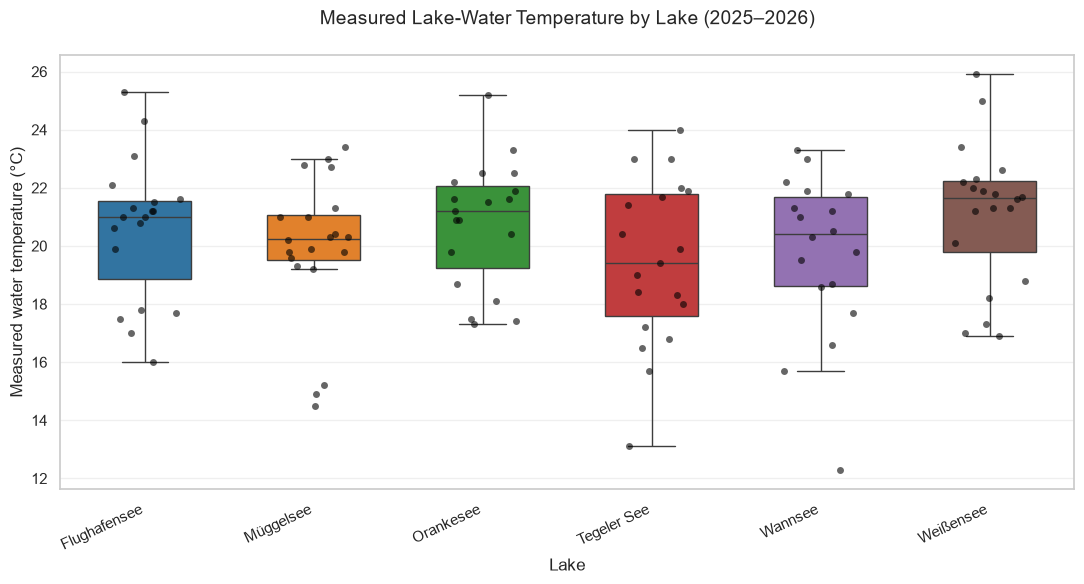

In [50]:
# Compare measured water-temperature distributions across lakes
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=water_temp_plot,
    x="lake",
    y="water_temperature_numeric",
    order=lake_order,
    hue="lake",
    hue_order=lake_order,
    palette=lake_palette,
    legend=False,
    showfliers=False,
    width=0.55
)

sns.stripplot(
    data=water_temp_plot,
    x="lake",
    y="water_temperature_numeric",
    order=lake_order,
    color="black",
    alpha=0.6,
    size=5,
    jitter=0.22
)

plt.title(
    "Measured Lake-Water Temperature by Lake (2025–2026)",
    fontsize=14,
    pad=22
)

plt.xlabel("Lake")
plt.ylabel("Measured water temperature (°C)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

- Warmest Median Temperatures: Weißensee (brown) records the highest median water temperature at 21.6°C, followed by Orankesee (green) at 21.2°C. Weißensee also reaches the highest recorded temperature, 25.9°C.
- Widest Temperature Range: Tegeler See (red) has the broadest observed range, from 13.1°C to 24.0°C, indicating greater variation among the sampled measurements.
- Similar Mid-Range Profiles: Flughafensee (blue), Müggelsee (orange), and Wannsee (purple) have relatively similar median temperatures, between 19.7°C and 21.0°C.
- Lower-Temperature Observations: Müggelsee and Wannsee include the lowest individual readings, 14.5°C and 12.3°C, respectively. These may reflect seasonal sampling differences rather than unusual water-temperature events.

# Water Quality & Temperature — Berlin Lakes

## Slide 1 — Methodology & Data Coverage

**Research question:** How do bacterial concentrations in Berlin's bathing lakes vary with temperature, and how do measured water temperatures differ between lakes?

**Data and approach**
- Six Berlin lakes: Flughafensee, Müggelsee, Orankesee, Tegeler See, Wannsee and Weißensee.
- Bacterial measurements: 2022–2026, matched by sampling date to the city's 7-day average daily maximum air temperature.
- Actual lake-water temperature measurements: 2025–2026, compared across the six lakes.
- Bacterial results reported below the quantification limit were excluded from the main scatterplots. Only unqualified numerical measurements were retained.
- Logarithmic scaling was used to make differences in bacterial concentrations easier to visualise.

**Important methodological distinction:** The bacterial analysis uses citywide air temperature as a proxy, not measured lake-water temperature. The measured-water-temperature analysis is a separate comparison.

**Limitations**
- The number of exact bacterial measurements differs by indicator: 91 for E. coli and 53 for intestinal enterococci.
- Measurements are unevenly distributed across lakes and dates.
- Some lakes have very few eligible observations, limiting lake-specific comparisons.
- The 115 measured water-temperature observations cover only 2025–2026.
- Observational patterns do not establish causation or identify the cause of individual elevated measurements.

## Slide 2 — Key Findings

**1. E. coli**
- Elevated measurements occur at different temperature levels, including some warmer periods.
- However, the overall dataset does not show a clear, consistent relationship between the 7-day average air temperature and E. coli concentration.
- No reliable temperature threshold can be established from these observations.

**2. Intestinal Enterococci**
- Some elevated measurements appear during warmer periods, particularly in Flughafensee and Weißensee.
- The overall analysis suggests a weak positive exploratory association with the 7-day average air temperature.
- This pattern is not sufficient to establish a temperature threshold or a causal relationship.
- A particularly high measurement in Tegeler See (4,005) occurred at a 7-day average air temperature of approximately 18°C. Its cause cannot be determined from this dataset.

**3. Measured Lake-Water Temperature**
- 115 valid measurements were available across the six lakes, with 18–20 observations per lake.
- Weißensee had the highest median temperature (21.6°C), followed by Orankesee (21.2°C).
- Tegeler See had the lowest recorded measurement (13.1°C) and a broad observed temperature range.
- The six lakes had relatively similar median temperatures, ranging from 19.4°C to 21.6°C.

## Overall Takeaway

The analysis identifies some elevated bacterial measurements during warmer periods, but it does not establish a consistent temperature-driven increase across all six lakes.

Measured lake-water temperatures were relatively similar across the lakes, although individual observations varied.

**Implication:** Temperature is a useful environmental variable to investigate alongside bathing-water quality, but it should not be used alone to infer bacterial contamination or bathing safety. Official bathing-water assessments and measurements remain essential.